# Deskripsi library yang digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memanggil Dataset

In [2]:
df = pd.read_csv('toyota.csv')

# Deskripsi Dataset

In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   object 
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   object 
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   object 
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), object(3)
memory usage: 473.9+ KB


# Visualisasi Data

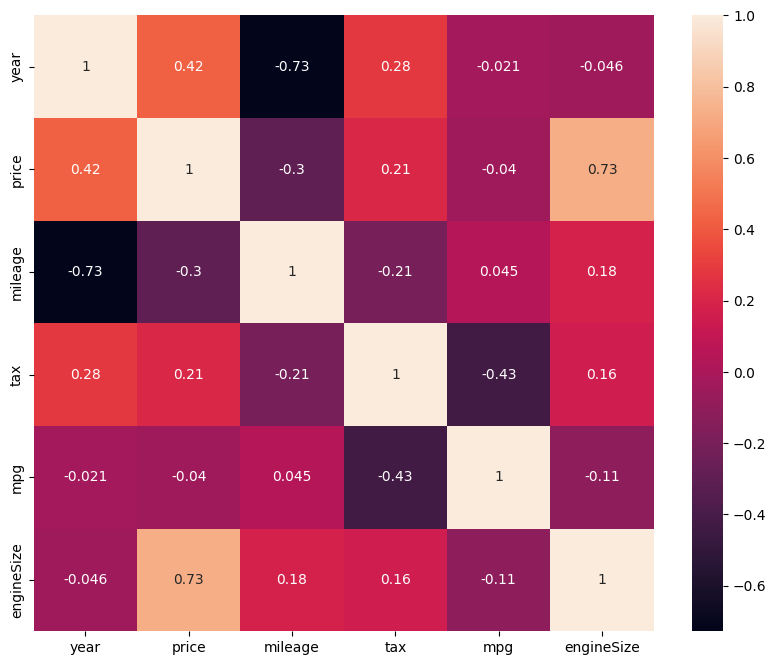

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

# Jumlah Mobil Berdasarkan Model

In [6]:
models = df.groupby('model').count()[['tax']].sort_values(by='tax', ascending=False).reset_index()
models = models.rename(columns={'tax': 'number_of_cars'})

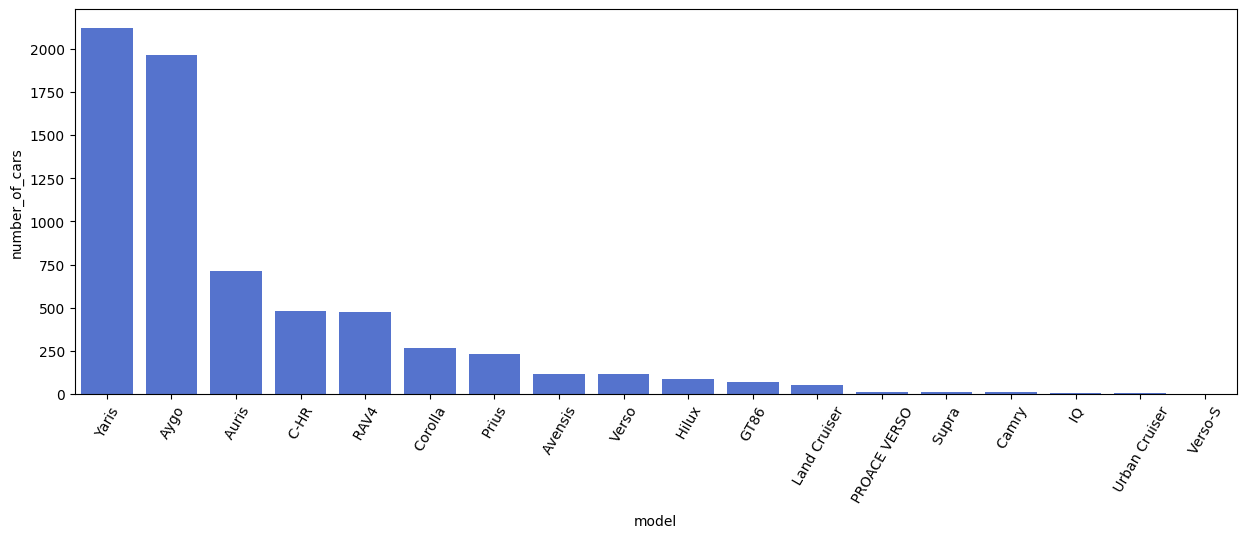

In [7]:
fig = plt.figure(figsize=(15, 5))
sns.barplot(x=models['model'], y=models['number_of_cars'], color='royalblue')
plt.xticks(rotation=60)
plt.show()

# Ukuran Mesin

In [8]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax', ascending=False).reset_index()
engine = engine.rename(columns={'tax': 'number_of_cars'})

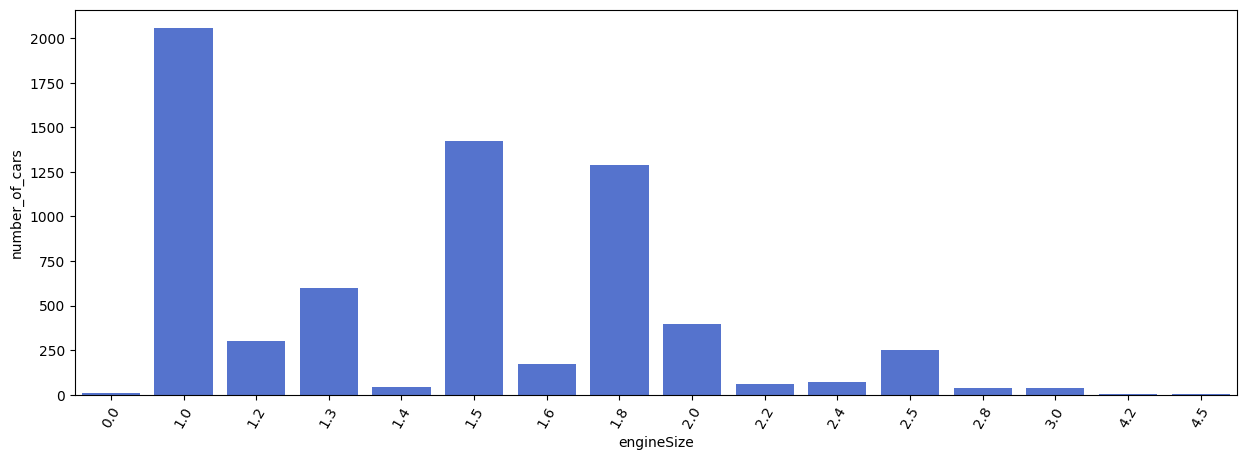

In [9]:
plt.figure(figsize=(15, 5))
sns.barplot(x=engine['engineSize'], y=engine['number_of_cars'], color='royalblue')
plt.xticks(rotation=60)
plt.show()

# Distribusi Mileagea

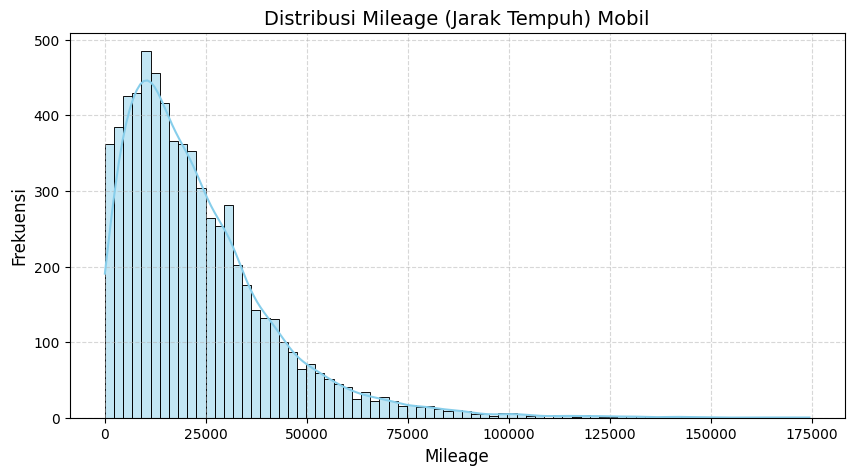

In [10]:
# Membuat visualisasi distribusi mileage dengan histogram dan garis kurva (KDE)
plt.figure(figsize=(10, 5))
sns.histplot(df['mileage'], kde=True, color='skyblue')

# Menambahkan judul dan label sumbu
plt.title('Distribusi Mileage (Jarak Tempuh) Mobil', fontsize=14)
plt.xlabel('Mileage', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# Menambahkan grid dan menampilkan grafik
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Distribusi Harga Mobil

Text(5.069444444444445, 0.5, 'Frekuensi')

<Figure size 1000x500 with 0 Axes>

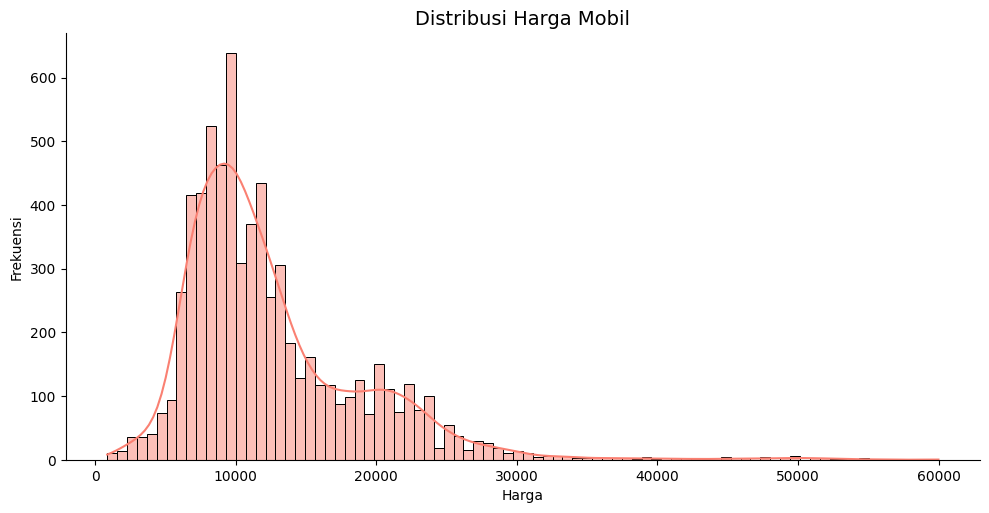

In [11]:
plt.figure(figsize=(10, 5))
sns.displot(df['price'], kde=True, color='salmon', height=5, aspect=2)
plt.title('Distribusi Harga Mobil', fontsize=14)
plt.xlabel('Harga')
plt.ylabel('Frekuensi')

Seleksi Fitur

In [12]:
features = ['year', 'mileage', 'tax', 'mpg', 'engineSize']
x = df[features]
y = df['price']
x.shape, y.shape

((6738, 5), (6738,))

Split Data Traning dan Data testing

In [13]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=70)
y_test.shape

(1348,)

Membuat Model Regresi Linier

In [14]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)
pred = lr.predict(x_test)

In [15]:
score = lr.score(x_test, y_test)
print(f'Akurasi model regresi linier: {score:.2f}')

Akurasi model regresi linier: 0.77


Membuat Inputan Model Regresi Linier

In [18]:
input_data = np.array([[2019, 5000, 145, 30.2, 2]])
predicted_price = lr.predict(input_data)
print('Estimasi harga mobil dalam EUR :', predicted_price)

Estimasi harga mobil dalam EUR : [21157.84667174]


c:\Users\ADVAN\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Save Model

In [17]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(lr, open(filename, 'wb'))